In [10]:
import numpy as np
import pandas as pd
from sksurv.linear_model import CoxPHSurvivalAnalysis
from sksurv.util import Surv
from sksurv.metrics import concordance_index_censored, concordance_index_ipcw
from sksurv.nonparametric import cumulative_incidence_competing_risks
import matplotlib.pyplot as plt

In [11]:
LANDMARK_DAYS = 1200
X_train = pd.read_csv("../data/processed/X_train.csv").astype(float)
X_test = pd.read_csv("../data/processed/X_test.csv").astype(float)
y_train = pd.read_csv("../data/processed/y_train.csv")
y_test = pd.read_csv("../data/processed/y_test.csv")

## Setup

In [12]:
# 0 = censored, 1 = adverse, 2 = transplant
def event_type(y):
    y['event_type'] = 0
    y.loc[y['event_adverse'] == 1, 'event_type'] = 1
    y.loc[y['event_transplant'] == 1, 'event_type'] = 2
    later = y['days_to_event'] > LANDMARK_DAYS
    y.loc[later, 'event_type'] = 0
    y.loc[later, 'days_to_event'] = LANDMARK_DAYS
    return y

y_train = event_type(y_train)
y_test = event_type(y_test)
print(y_train['event_type'].value_counts())


event_type
0    190735
2    165198
1     39909
Name: count, dtype: int64


## Cox Model

In [13]:
surv_train = Surv.from_arrays(event=(y_train['event_type'] == 1), time=y_train['days_to_event'])
surv_test = Surv.from_arrays(event=(y_test['event_type'] == 1), time=y_test['days_to_event'])

cox = CoxPHSurvivalAnalysis(alpha=0.01)
cox.fit(X_train, surv_train)
risk_scores = cox.predict(X_test)

hazard_ratios = pd.Series(np.exp(cox.coef_), index=X_train.columns)
print(hazard_ratios.sort_values(ascending=False))

functional_scale_not_applicable_infant    2.658513
INIT_STAT_4060                            2.473324
INIT_AGE                                  1.716509
DIALYSIS_DURATION_LOG                     1.597207
functional_percent_missing                1.500516
ABO_A2B                                   1.496113
REGION_4                                  1.413044
REGION_10                                 1.301101
REGION_11                                 1.244656
REGION_3                                  1.167645
ABO_AB                                    1.125832
AGE_DIALYSIS_INTERACTION                  1.101348
REGION_7                                  1.100306
ABO_A2                                    1.089945
POLICY_ERA_post_2021                      1.087666
REGION_2                                  1.075312
REGION_6                                  1.068694
REGION_9                                  1.064284
REGION_8                                  1.058247
INIT_STAT_4099                 

## C-Index

In [14]:
c_index1 = concordance_index_censored(surv_test['event'], surv_test['time'], risk_scores)[0]
print("C-Index1:", round(c_index1, 3))

c_index2 = concordance_index_ipcw(surv_train, surv_test, risk_scores, tau=1100)[0]
print("C-Index2:", round(c_index2, 3))


C-Index1: 0.694
C-Index2: 0.689


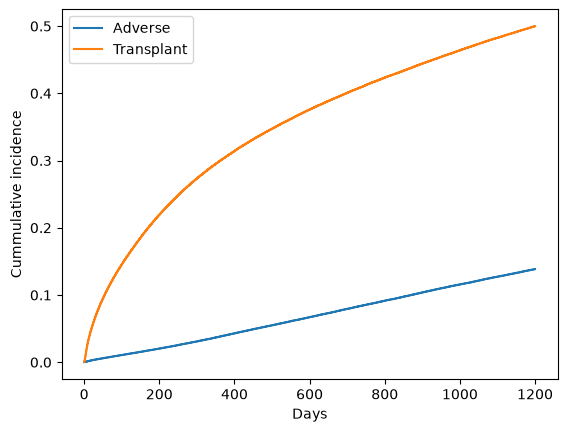

In [15]:
times, cif = cumulative_incidence_competing_risks(
    y_train['event_type'].values, y_train['days_to_event'].values
)

# cif[0] = any event, cif[1] = adverse, cif[2] = transplant

plt.step(times, cif[1], where="post", label="Adverse")
plt.step(times, cif[2], where="post", label="Transplant")
plt.xlabel("Days")
plt.ylabel("Cummulative incidence")
plt.legend()

In [16]:
for cause, name in {1: "Adverse", 2: "Transplant"}.items():
    s_tr = Surv.from_arrays(event=(y_train["event_type"] == cause), time=y_train["days_to_event"])
    s_te = Surv.from_arrays(event=(y_test["event_type"] == cause),  time=y_test["days_to_event"])

    m = CoxPHSurvivalAnalysis(alpha=0.01).fit(X_train, s_tr)
    c = concordance_index_censored(s_te["event"], s_te["time"], m.predict(X_test))[0]
    print(f"{name}: C-index = {c:.3f}")

Adverse: C-index = 0.694
Transplant: C-index = 0.676
